# A conversion lift worth investigating
## E-commerce experiment analysis

The source is a public educational dataset, not independently verified production telemetry.

**Decision question:** How large is the treatment-control conversion difference, how uncertain is it, and does accounting for country change the interpretation?

The primary estimand is the difference in conversion probability per recorded observation. We select a two-sided test of equal conversion probabilities at alpha=0.05 and a 95% Newcombe score interval. This is a retrospective analysis, not a preregistered experiment.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.analysis import run
m,summary,countries,audit,regression=run()
display(Markdown(f"**Source and analysis population:** {m['source_rows']:,} observations. All source rows retained."))
display(audit)

**Source and analysis population:** 69,889 observations. All source rows retained.

,step,count,decision
0,Source rows,69889,"Immutable source, verified SHA-256"
1,Missing or invalid rows,0,None removed; unexpected values halt analysis
2,Repeated three-field tuples,69877,Retained: repeated categories are not evidence...
3,Analysis rows,69889,"No exclusions, imputation or deduplication"


## A trustworthy denominator starts with the actual schema

The source contains only `country`, `group`, and `converted`. There are no missing fields, unexpected country/group values, or nonbinary outcomes. The analysis fails on an unreviewed source checksum or invalid values. It makes no exclusions or imputations.

Repeated three-field tuples are retained: many legitimate observations have the same country, group, and outcome. Deduplicating these would collapse the dataset into a few category combinations. Without identifiers, distinct visitors and repeated exposure cannot be checked. Without dates, duration and seasonality cannot be checked.

Country codes are CA, UK, US. Control is the comparison baseline and treatment is the exposed group label. This analysis interprets converted=1 as conversion and 0 as no conversion. Conversion's exact business definition and measurement window are not documented in the CSV.

,n,conversions,rate,ci_low,ci_high
group,,,,,
control,34678,3650,0.105254,0.102068,0.108528
treatment,35211,5469,0.155321,0.151575,0.159142


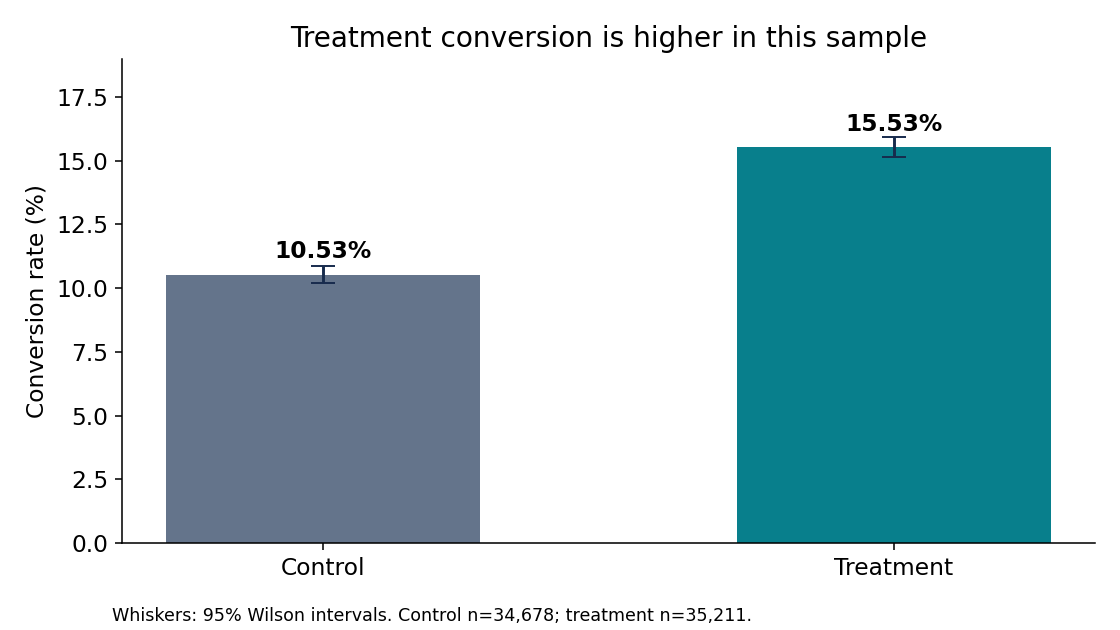

Treatment minus control: **5.007 percentage points**. Relative lift: **47.57%**. These quantities have different denominators.

In [2]:
display(summary)
display(Image(filename=str(ROOT/'results/charts/conversion.png')))
display(Markdown(f"Treatment minus control: **{100*m['risk_difference']:.3f} percentage points**. Relative lift: **{100*m['relative_lift']:.2f}%**. These quantities have different denominators."))

## Estimate the effect, then test the null

The pooled two-proportion z test uses the combined conversion rate under the null and assumes independent Bernoulli observations. The Newcombe interval combines Wilson intervals for the two groups and avoids relying on a simple Wald difference interval. Both groups have thousands of conversions and nonconversions, supporting the large-sample test approximation.

The test addresses equal underlying rates under its assumptions. A small p-value is not the probability that the null is true, proof of randomization, or evidence of a profitable launch.

z = **19.6472**; two-sided p = **6.104e-86**. 95% Newcombe interval = **[4.509, 5.504] percentage points**. The interval excludes zero.

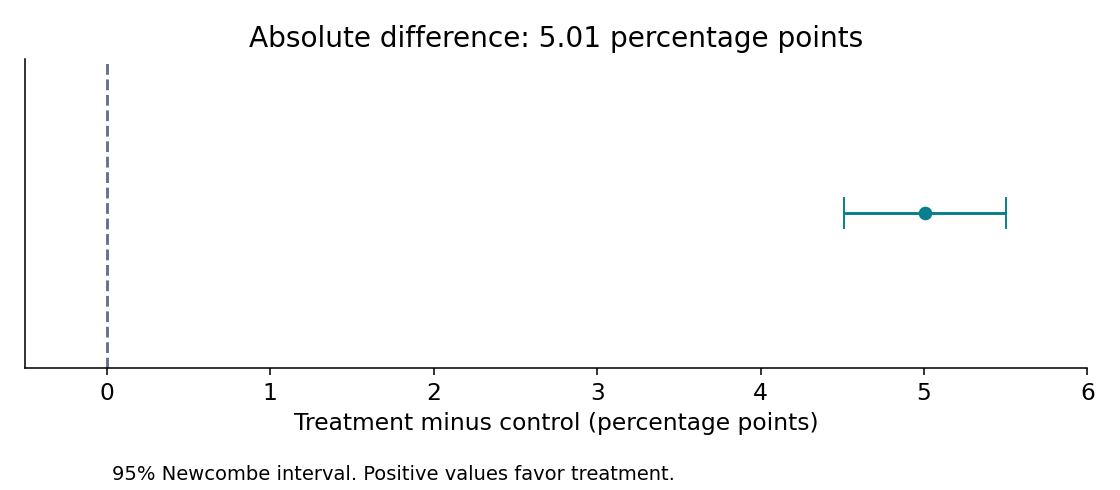

In [3]:
display(Markdown(f"z = **{m['z']:.4f}**; two-sided p = **{m['p_value']:.3e}**. 95% Newcombe interval = **[{100*m['ci_low']:.3f}, {100*m['ci_high']:.3f}] percentage points**. The interval excludes zero."))
display(Image(filename=str(ROOT/'results/charts/effect.png')))

## Country as a regression cross-check

Two logistic models estimate conversion: (1) intercept plus treatment indicator, and (2) intercept, treatment, CA and UK indicators. Control is the group baseline; US is the country baseline. No interactions are fitted. Country coefficients describe differences relative to US conditional on group, not causal country effects.

The treatment coefficient is a log odds ratio. Exponentiating gives a conditional odds ratio, not a probability ratio or percentage-point lift. The additive adjusted model assumes a common treatment odds ratio across countries. It is a sensitivity cross-check, not a replacement primary analysis.

The standardized difference averages adjusted predictions under treatment and control over the pooled observed country distribution. It is a point estimate only; the primary Newcombe interval must not be attached to this adjusted quantity.

,model,coefficient,odds_ratio,or_ci_low,or_ci_high,p_value
0,Unadjusted,0.446698,1.563143,1.494646,1.634778,5.130361e-85
1,Country adjusted,0.446618,1.563017,1.494521,1.634652,5.665097e-85


,country,group,n,conversions,rate,within_group_share
0,CA,control,1683,159,0.094474,0.048532
1,CA,treatment,1805,278,0.154017,0.051262
2,UK,control,8795,894,0.101649,0.253619
3,UK,treatment,8756,1302,0.148698,0.248672
4,US,control,24200,2597,0.107314,0.697849
5,US,treatment,24650,3889,0.157769,0.700065


Country-standardized adjusted difference: **5.005 percentage points**.

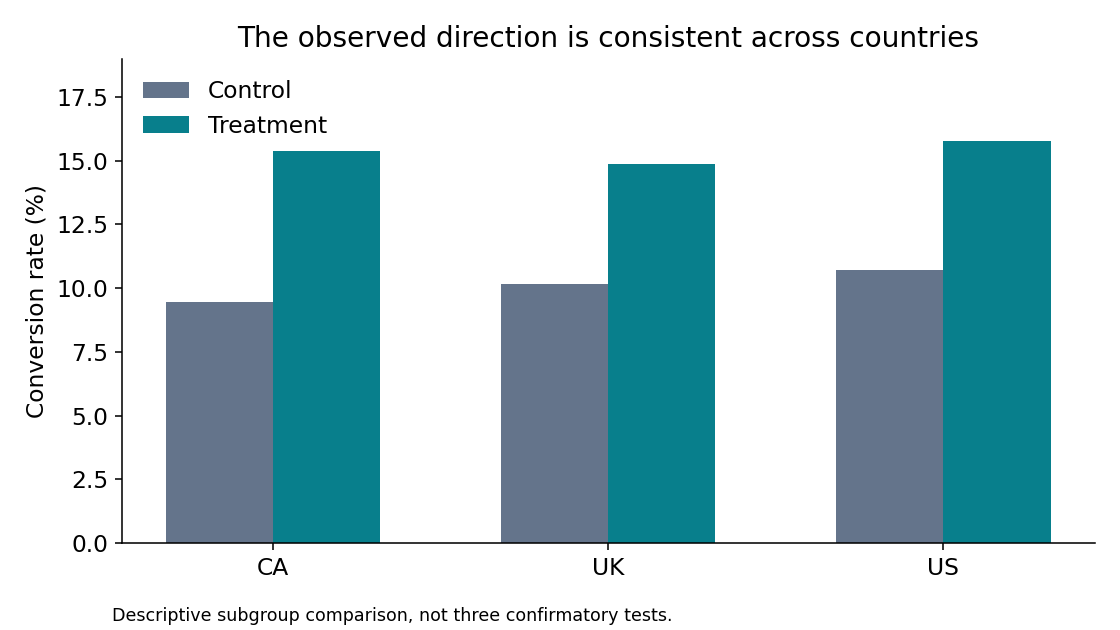

In [4]:
display(regression)
display(countries)
display(Markdown(f"Country-standardized adjusted difference: **{100*m['country_standardized_risk_difference']:.3f} percentage points**."))
display(Image(filename=str(ROOT/'results/charts/country.png')))

## From statistical evidence to a business decision

The observed conversion improvement is statistically clear under independence assumptions and remains similar after country adjustment. Country comparisons are descriptive, with no separate confirmatory subgroup tests.

The dataset provides no revenue, implementation cost, safety metrics, retention, planned allocation ratio, randomization record, stopping rule, or minimum worthwhile effect. Therefore this analysis does not make an unconditional launch or ROI recommendation. First verify assignment, unit independence, logging, experiment duration, and the intended allocation ratio. Then compare the effect interval against a business-defined minimum worthwhile improvement and guardrails.

Do not assume equal intended group sizes: the split is observable, but the planned allocation is unknown. **Conditional diagnostic:** if intended allocation was exactly 50:50, an exact two-sided binomial test of 35,211 treatment observations out of 69,889 gives p approximately 0.04418. This would warrant investigating assignment and logging under that assumption. It is not proof of broken randomization, does not establish the intended ratio, and causes no row exclusions. The exact computed value is saved in metrics.json. Repeated users, selective reporting, or optional stopping could invalidate nominal uncertainty. Educational data may not represent real customer behavior.

## Data reuse

All public outputs are aggregates. The original CSV remains local and excluded from publication because redistribution permission was not established. Source URL, checksum, software versions, and methods are recorded in the source documentation and requirements file.

Sources: [dataset](https://video.udacity-data.com/topher/2023/February/63f67d64_ab_data/ab_data.csv), [two-proportion test](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportions_ztest.html), [difference interval](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.confint_proportions_2indep.html).